Camile Silva

Gustavo Ferreira

Lucas Caetano

Marco Conte

Sofia Rodrigues

# 🗳️ Jornada de Estatística Descritiva — Eleições 2022: Presidente e Governador

**Base:** *Brazil Elections 2022* (Kaggle / dados oficiais do TSE) — os **4 arquivos** do conjunto
**Recorte:** só os cargos de **Presidente** e **Governador**
**Objetivo:** conduzir uma análise descritiva completa (tendência central, dispersão, distribuição, correlação, segmentações, outliers e storytelling) sobre **como o Brasil votou** nesses dois cargos.
**Instruções:** execute célula por célula. Depois de cada bloco de código há uma célula de texto explicando o resultado.

**Por que só Presidente e Governador?** São os únicos cargos que aparecem nos 4 arquivos (só eles tiveram 2º turno). Assim dá para comparar 1º e 2º turno e cruzar **quem votou** com **em quem votou**.

---

Jornada Completa de Estatística Descritiva (com base Eleições 2022)

🔹 1. Introdução ao Dataset

Objetivo: entender como o comparecimento, o voto nulo e o desempenho dos candidatos variam entre regiões, estados e turnos.

Perguntas iniciais:

Como está estruturado o dataset?

Quantas zonas eleitorais, candidatos e estados temos registrados?

Quais variáveis são categóricas e quais são numéricas?

🔹 2. Tendência Central

Métricas: média, mediana, moda.

Perguntas:

Qual é o comparecimento médio de uma zona eleitoral?

A média e a mediana contam a mesma história?

Qual candidato a Presidente teve a maior mediana de votos por zona?

🔹 3. Dispersão

Métricas: variância, desvio padrão, coeficiente de variação, quartis.

Perguntas:

O voto nulo é mais disperso que o comparecimento?

Qual candidato teve a votação mais parecida em todas as zonas?

🔹 4. Distribuições

Visualizações: histograma, curtose, assimetria.

Perguntas:

O comparecimento segue uma distribuição próxima da normal?

Como se distribui a votação do vencedor pelas zonas?

🔹 5. Relações entre Variáveis

Métricas: correlação.

Perguntas:

Onde o vencedor teve mais votos houve mais ou menos voto nulo?

Essa relação continua valendo dentro de cada região?

O eleitor mudou de voto entre o 1º e o 2º turno?

🔹 6. Segmentações

Grupos de análise: região, estado, turno, candidato.

Perguntas:

Quais regiões e estados tiveram maior comparecimento?

Como ficaram as disputas para governador?

🔹 7. Outliers

Métodos: boxplot, z-score, IQR.

Perguntas:

Existem zonas com comparecimento ou voto nulo muito fora do padrão?

São erro de dado ou fenômeno real?

🔹 8. Visualização e Storytelling

Gráficos: boxplot, scatter, matriz de correlação.

🔹 9. Síntese e Interpretação

Produto final: resumo dos achados em formato de relatório.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

zonas_1t = pd.read_csv("/content/detalhe_votacao.csv/detalhe_votacao.csv")
zonas_2t = pd.read_csv("/content/detalhe_votacao_2_turno.csv/detalhe_votacao_2_turno.csv")
cand_2t = pd.read_csv("/content/votacao_candidato_2_turno.csv/votacao_candidato_2_turno.csv")

cand_1t = pd.read_csv("/content/votacao_candidato.csv/votacao_candidato.csv")

print("Zonas - 1º turno:", zonas_1t.shape)
print("Zonas - 2º turno:", zonas_2t.shape)
print("Candidatos - 1º turno:", cand_1t.shape)
print("Candidatos - 2º turno:", cand_2t.shape)

Zonas - 1º turno: (30692, 16)
Zonas - 2º turno: (9275, 16)
Candidatos - 1º turno: (9383568, 14)
Candidatos - 2º turno: (18550, 14)


> **O que cada arquivo traz**
>
> | | **1º turno** | **2º turno** |
> |---|---|---|
> | **Total por zona** (quem votou) | `detalhe_votacao.csv` | `detalhe_votacao_2_turno.csv` |
> | **Por candidato** (em quem votou) | `votacao_candidato.csv` | `votacao_candidato_2_turno.csv` |
>
> - Os arquivos **de zona** dizem quantas pessoas podiam votar, quantas foram, e quantos votos foram válidos, brancos e nulos. **Não dizem em quem votaram.**
> - Os arquivos **de candidato** dizem quantos votos cada candidato teve em cada zona. **Não trazem branco, nulo nem abstenção.**
> - Um completa o outro. Na seção 4 vamos **juntar os dois** numa tabela só.

In [ ]:

# 1.1)
for col in ["nr_turno", "cd_municipio", "qt_total_votos_nulos"]:
    zonas_2t[col] = pd.to_numeric(zonas_2t[col], errors="coerce")

print("Linhas com defeito (turno vazio):", zonas_2t["nr_turno"].isna().sum())


zonas_2t = zonas_2t[zonas_2t["nr_turno"] == 2]
print("Zonas - 2º turno depois da correção:", zonas_2t.shape)

Linhas com defeito (turno vazio): 2
Zonas - 2º turno depois da correção: (9273, 16)


In [ ]:
# ==============================
# 1.2) Filtro dos cargos e união dos turnos
# ==============================
# Ficamos só com Presidente e Governador. O símbolo | significa "ou".
zonas_1t = zonas_1t[(zonas_1t["ds_cargo"] == "Presidente") | (zonas_1t["ds_cargo"] == "Governador")]
zonas_2t = zonas_2t[(zonas_2t["ds_cargo"] == "Presidente") | (zonas_2t["ds_cargo"] == "Governador")]
cand_1t = cand_1t[(cand_1t["ds_cargo"] == "Presidente") | (cand_1t["ds_cargo"] == "Governador")]
cand_2t = cand_2t[(cand_2t["ds_cargo"] == "Presidente") | (cand_2t["ds_cargo"] == "Governador")]

# Ele "empilha" uma tabela embaixo da outra. Usamos para juntar 1º e 2º turno.
zonas = pd.concat([zonas_1t, zonas_2t])
candidatos = pd.concat([cand_1t, cand_2t])

print("Tabela de zonas:", zonas.shape)
print("Tabela de candidatos:", candidatos.shape)

# Quantas zonas de cada cargo e turno ficaram
for (cargo, turno), subset in zonas.groupby(["ds_cargo", "nr_turno"]):
    print(f"{cargo} - {turno:.0f}º turno: {subset.shape[0]} zonas")

Tabela de zonas: (21658, 16)
Tabela de candidatos: (140620, 14)
Governador - 1º turno: 6102 zonas
Governador - 2º turno: 2991 zonas
Presidente - 1º turno: 6283 zonas
Presidente - 2º turno: 6282 zonas


> **Perguntas-guia**
> - Como está estruturado o dataset?
> - Quantas zonas eleitorais, candidatos e estados temos registrados?
> - Quais variáveis são categóricas e quais são numéricas?

In [ ]:
# ==============================
# 2) Visão geral e dicionário rápido
# ==============================
# TABELA DE ZONAS (uma linha = uma zona eleitoral, em um cargo, em um turno)
#   ds_cargo              -> cargo (Presidente ou Governador)
#   cd_municipio          -> código do município (só identifica, não é medida)
#   nm_municipio          -> nome do município
#   nr_turno              -> 1º ou 2º turno
#   sg_uf                 -> sigla do estado; 'ZZ' = votos no exterior
#   nr_zona               -> número da zona eleitoral (só identifica)
#   qt_aptos_tot          -> quantas pessoas podiam votar
#   qt_comparecimento     -> quantas foram votar
#   qt_votos_validos      -> votos dados a algum candidato
#   qt_votos_brancos      -> votos em branco
#   qt_total_votos_nulos  -> votos nulos
info = zonas.info()
display(zonas.sample(5, random_state=42))
display(zonas.describe(include="all").transpose())

<class 'pandas.core.frame.DataFrame'>
Index: 21658 entries, 12205 to 9274
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ds_cargo                 21658 non-null  object 
 1   cd_municipio             21658 non-null  float64
 2   nm_municipio             21658 non-null  object 
 3   nr_turno                 21658 non-null  float64
 4   sg_uf                    21658 non-null  object 
 5   nr_zona                  21658 non-null  int64  
 6   qt_secoes_agregadas      21658 non-null  int64  
 7   qt_aptos_tot             21658 non-null  int64  
 8   qt_comparecimento        21658 non-null  int64  
 9   qt_votos_nom_validos     21658 non-null  int64  
 10  qt_votos_brancos         21658 non-null  int64  
 11  qt_total_vt_leg_validos  21658 non-null  int64  
 12  qt_total_votos_anulados  21658 non-null  int64  
 13  qt_votos_validos         21658 non-null  int64  
 14  qt_votos                

,ds_cargo,cd_municipio,nm_municipio,nr_turno,sg_uf,nr_zona,qt_secoes_agregadas,qt_aptos_tot,qt_comparecimento,qt_votos_nom_validos,qt_votos_brancos,qt_total_vt_leg_validos,qt_total_votos_anulados,qt_votos_validos,qt_votos,qt_total_votos_nulos
18337,Presidente,531.0,CASTANHEIRAS,1.0,RO,15,0,3075,2296,2250,19,0,0,2250,2296,27.0
21289,Presidente,48534.0,MONTALVÂNIA,1.0,MG,342,7,13064,8952,8510,96,0,0,8510,8952,346.0
19406,Presidente,17752.0,PARAZINHO,1.0,RN,52,1,5057,4209,4048,39,0,0,4048,4209,122.0
13680,Governador,24279.0,GRAVATÁ,1.0,PE,30,8,68849,54213,44681,3767,0,0,44681,54213,5765.0
5090,Presidente,35700.0,IGRAPIÚNA,2.0,BA,32,10,10093,6658,6201,106,0,0,6201,6658,351.0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ds_cargo,21658,2,Presidente,12565,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cd_municipio,21658.0,NaN,NaN,NaN,52251.220981,28753.959365,19.0,27158.0,54011.0,79219.0,99473.0
nm_municipio,21658,5613,SÃO PAULO,232,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nr_turno,21658.0,NaN,NaN,NaN,1.428156,0.494823,1.0,1.0,1.0,2.0,2.0
sg_uf,21658,28,SP,3120,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nr_zona,21658.0,NaN,NaN,NaN,92.975159,87.091493,1.0,28.0,65.0,132.0,427.0
qt_secoes_agregadas,21658.0,NaN,NaN,NaN,3.615846,7.648093,0.0,0.0,1.0,4.0,134.0
qt_aptos_tot,21658.0,NaN,NaN,NaN,25455.515652,35612.561759,1.0,4948.5,10405.0,25366.5,282854.0
qt_comparecimento,21658.0,NaN,NaN,NaN,20188.47165,28646.940741,0.0,3905.0,7994.0,19604.75,226316.0
qt_votos_nom_validos,21658.0,NaN,NaN,NaN,18723.650476,26436.947074,0.0,3633.25,7469.0,18314.5,211515.0


In [ ]:
# TABELA DE CANDIDATOS (uma linha = um candidato, em uma zona, em um turno)
#   nm_candidato, nr_candidato, sg_partido -> quem é o candidato
#   nm_regiao             -> região do Brasil (ou EXTERIOR)
#   ds_sit_totalizacao    -> resultado: Eleito, Não Eleito ou Segundo turno
#   qt_votos_nominais     -> votos do candidato naquela zona
#   qt_votos_validos      -> total de votos válidos da zona (igual para todos os candidatos)
info = candidatos.info()
display(candidatos.sample(5, random_state=42))

<class 'pandas.core.frame.DataFrame'>
Index: 140620 entries, 9211183 to 18549
Data columns (total 14 columns):
 #   Column              Non-Null Count   Dtype 
---  ------              --------------   ----- 
 0   ds_cargo            140620 non-null  object
 1   cd_municipio        140620 non-null  int64 
 2   nm_municipio        140620 non-null  object
 3   nm_candidato        140620 non-null  object
 4   nr_candidato        140620 non-null  int64 
 5   sg_partido          140620 non-null  object
 6   nm_regiao           140620 non-null  object
 7   ds_sit_totalizacao  140620 non-null  object
 8   nr_turno            140620 non-null  int64 
 9   sg_uf               140620 non-null  object
 10  nr_zona             140620 non-null  int64 
 11  qt_votos_nominais   140620 non-null  int64 
 12  qt_votos_validos    140620 non-null  int64 
 13  dt_carga            140620 non-null  object
dtypes: int64(6), object(8)
memory usage: 16.1+ MB


,ds_cargo,cd_municipio,nm_municipio,nm_candidato,nr_candidato,sg_partido,nm_regiao,ds_sit_totalizacao,nr_turno,sg_uf,nr_zona,qt_votos_nominais,qt_votos_validos,dt_carga
9253048,Governador,81752,JARAGUÁ DO SUL,JORGE CATARINO LEONARDELI BOEIRA,12,PDT,SUL,Não Eleito,1,SC,87,239,49566,2022-11-04 15:55:26
9256918,Governador,87173,IVOTI,EDUARDO FIGUEIREDO CAVALHEIRO LEITE,45,PSDB,SUL,Segundo turno,1,RS,118,3192,13656,2022-11-04 15:55:26
9235756,Governador,51934,SANTA ROSA DA SERRA,LORENE FIGUEIREDO DE OLIVEIRA,50,PSOL,SUDESTE,Não Eleito,1,MG,327,2,2165,2022-11-04 15:55:26
9329712,Presidente,93106,BURITI DE GOIÁS,JAIR MESSIAS BOLSONARO,22,PL,CENTRO-OESTE,Segundo turno,1,GO,34,1575,2575,2022-11-04 15:55:26
9234223,Governador,48950,NOVA LIMA,ALEXANDRE KALIL,55,PSD,SUDESTE,Não Eleito,1,MG,194,23039,54028,2022-11-04 15:55:26


In [ ]:
# Números para ter noção do tamanho da base
print("Municípios:", len(zonas["nm_municipio"].unique()))
print("Estados (com 'ZZ' = exterior):", len(zonas["sg_uf"].unique()))
print("Candidatos a Presidente:",
      len(candidatos[candidatos["ds_cargo"] == "Presidente"]["nm_candidato"].unique()))
print("Candidatos a Governador:",
      len(candidatos[candidatos["ds_cargo"] == "Governador"]["nm_candidato"].unique()))

gov_2t = zonas[(zonas["ds_cargo"] == "Governador") & (zonas["nr_turno"] == 2)]
print("Estados com 2º turno para Governador:", gov_2t["sg_uf"].unique())

# Colunas de texto (categóricas) e de número (numéricas)
print("\nCategóricas:", zonas.select_dtypes(exclude=[np.number]).columns.tolist())
print("Numéricas:", zonas.select_dtypes(include=[np.number]).columns.tolist())

Municípios: 5613
Estados (com 'ZZ' = exterior): 28
Candidatos a Presidente: 11
Candidatos a Governador: 213
Estados com 2º turno para Governador: ['RO' 'AM' 'PB' 'PE' 'AL' 'BA' 'SE' 'MS' 'ES' 'SP' 'SC' 'RS']

Categóricas: ['ds_cargo', 'nm_municipio', 'sg_uf']
Numéricas: ['cd_municipio', 'nr_turno', 'nr_zona', 'qt_secoes_agregadas', 'qt_aptos_tot', 'qt_comparecimento', 'qt_votos_nom_validos', 'qt_votos_brancos', 'qt_total_vt_leg_validos', 'qt_total_votos_anulados', 'qt_votos_validos', 'qt_votos', 'qt_total_votos_nulos']


> **Respostas**
> - Temos **21.658 linhas de zonas** e **140.620 linhas de candidatos**, cobrindo **5.613 municípios** (o número inclui as cidades do exterior), os **27 estados e o exterior**.
> - Foram **11 candidatos a Presidente** e **213 a Governador**. Houve 2º turno para Governador em **12 estados**.
> - **Categóricas:** cargo, município e estado (e, na tabela de candidatos, candidato, partido, região e situação). O turno é número, mas funciona como categoria (1 ou 2).
> - **Numéricas:** as colunas que começam com `qt_` (quantidades).
> - Código do município e número da zona **só identificam** a linha, não entram nas contas.
> - As quantidades dependem do tamanho da zona (uma zona de São Paulo tem 150 mil eleitores, uma do interior tem 2 mil). Por isso, na seção 4, vamos transformar tudo em **porcentagem**.

In [ ]:
# ==============================
# 3) Qualidade dos dados
# ==============================
# Valores nulos e duplicados
null_counts = zonas.isna().sum().sort_values(ascending=False)
dup_rows = zonas.duplicated().sum()

print("Duplicados (linhas) - zonas:", dup_rows)
print("Duplicados (linhas) - candidatos:", candidatos.duplicated().sum())
display(null_counts.to_frame("nulos_zonas"))
display(candidatos.isna().sum().sort_values(ascending=False).to_frame("nulos_candidatos"))

# Colunas totalmente nulas
totally_null_cols = [c for c in zonas.columns if zonas[c].isna().all()]
print("Colunas totalmente nulas:", totally_null_cols)

Duplicados (linhas) - zonas: 0
Duplicados (linhas) - candidatos: 0


,nulos_zonas
ds_cargo,0
cd_municipio,0
nm_municipio,0
nr_turno,0
sg_uf,0
nr_zona,0
qt_secoes_agregadas,0
qt_aptos_tot,0
qt_comparecimento,0
qt_votos_nom_validos,0


,nulos_candidatos
ds_cargo,0
cd_municipio,0
nm_municipio,0
nm_candidato,0
nr_candidato,0
sg_partido,0
nm_regiao,0
ds_sit_totalizacao,0
nr_turno,0
sg_uf,0


Colunas totalmente nulas: []


In [ ]:
# Testes de bom senso próprios de dados de eleição

# 3.1) Não pode ter mais gente votando do que gente apta a votar
print("Zonas com comparecimento maior que aptos:",
      (zonas["qt_comparecimento"] > zonas["qt_aptos_tot"]).sum())

# 3.2) Zonas onde ninguém votou (vão dar divisão por zero nas porcentagens)
sem_votos = zonas[zonas["qt_comparecimento"] == 0]
print("Zonas com comparecimento zero:", sem_votos.shape[0], "| estados:", sem_votos["sg_uf"].unique())

# 3.3) A soma dos votos dos candidatos deveria bater com os votos válidos das zonas
conferencia = pd.DataFrame({
    "soma_votos_candidatos": candidatos.groupby(["ds_cargo", "nr_turno"])["qt_votos_nominais"].sum(),
    "votos_validos_zonas": zonas.groupby(["ds_cargo", "nr_turno"])["qt_votos_nom_validos"].sum(),
})
conferencia["diferenca"] = conferencia["soma_votos_candidatos"] - conferencia["votos_validos_zonas"]
display(conferencia)

Zonas com comparecimento maior que aptos: 0
Zonas com comparecimento zero: 84 | estados: ['ZZ']


soma_votos_candidatos  votos_validos_zonas  diferenca
ds_cargo   nr_turno                                                       
Governador 1                     108486046            108448349      37697
           2                      60290547             60288494       2053
Presidente 1                     118229719            118229719          0
           2                     118552353            118550260       2093

> **Observações**
> - **Nenhum valor nulo, nenhuma linha duplicada e nenhuma coluna vazia.** É dado oficial do TSE. Diferente do notebook de futebol (que tinha a coluna `status` 100% nula), aqui não há coluna para remover.
> - Nenhuma zona tem mais votantes do que eleitores aptos.
> - **84 zonas do exterior tiveram comparecimento zero** (postos consulares com poucos eleitores, onde ninguém votou). Não é erro. Mas nelas as porcentagens de branco e nulo vão ficar vazias (`NaN`), porque não dá para dividir por zero.
> - **A soma dos votos dos candidatos bate com os votos válidos** para Presidente no 1º turno. As pequenas diferenças têm explicação:
>   - **2º turno:** são as 2 zonas com defeito que removemos na seção 1.1 (elas continuam no arquivo de candidatos).
>   - **Governador no 1º turno:** são votos de alguns candidatos pequenos que o TSE não contou como válidos (o motivo provável é pendência no registro da candidatura). É menos de 0,05% dos votos.
> - **Decisão:** manter todas as linhas.

In [ ]:
# ==============================
# 4) Preparação mínima
# ==============================
# A coluna dt_carga (data em que o TSE carregou o arquivo) não serve para a análise
candidatos = candidatos.drop(columns=["dt_carga"])

# Contagens não servem para comparar zonas de tamanhos diferentes; porcentagens sim.
# Comparecimento e abstenção: sobre quem podia votar
zonas["taxa_comparecimento"] = zonas["qt_comparecimento"] / zonas["qt_aptos_tot"] * 100
zonas["taxa_abstencao"] = 100 - zonas["taxa_comparecimento"]

# Branco, nulo e válido: sobre quem foi votar
zonas["taxa_brancos"] = zonas["qt_votos_brancos"] / zonas["qt_comparecimento"] * 100
zonas["taxa_nulos"] = zonas["qt_total_votos_nulos"] / zonas["qt_comparecimento"] * 100
zonas["taxa_validos"] = zonas["qt_votos_validos"] / zonas["qt_comparecimento"] * 100

taxas = ["taxa_comparecimento", "taxa_abstencao", "taxa_brancos", "taxa_nulos", "taxa_validos"]
display(zonas[["ds_cargo", "nr_turno", "sg_uf"] + taxas].head())

,ds_cargo,nr_turno,sg_uf,taxa_comparecimento,taxa_abstencao,taxa_brancos,taxa_nulos,taxa_validos
12205,Governador,1.0,RO,74.398863,25.601137,2.883468,4.511386,92.605146
12206,Governador,1.0,RO,80.132843,19.867157,3.118776,4.801603,92.079621
12207,Governador,1.0,RO,77.717714,22.282286,3.557196,5.299766,91.143038
12208,Governador,1.0,RO,79.309337,20.690663,3.277842,5.160796,91.561362
12209,Governador,1.0,RO,78.182552,21.817448,3.853613,5.969007,90.177380


In [ ]:
# ==============================
# 4.1) Junção das tabelas de candidatos e de zonas
# ==============================
# O merge junta duas tabelas usando colunas que elas têm em comum.
# Cada zona é identificada pelo cargo, município, número da zona e turno.
chave = ["ds_cargo", "cd_municipio", "nr_zona", "nr_turno"]
colunas_zona = chave + ["qt_aptos_tot", "qt_comparecimento"] + taxas

base = candidatos.merge(zonas[colunas_zona], on=chave)

print("Linhas de candidatos:", candidatos.shape[0])
print("Linhas depois da junção:", base.shape[0])

# Porcentagem dos votos válidos que o candidato teve na zona ("share").
# Exemplo: share 60 = o candidato teve 60% dos votos válidos daquela zona.
base["share"] = base["qt_votos_nominais"] / base["qt_votos_validos"] * 100

display(base[["ds_cargo", "nr_turno", "sg_uf", "nm_regiao", "nm_candidato",
              "qt_votos_nominais", "share", "taxa_comparecimento", "taxa_nulos"]].head())

Linhas de candidatos: 140620
Linhas depois da junção: 140616


,ds_cargo,nr_turno,sg_uf,nm_regiao,nm_candidato,qt_votos_nominais,share,taxa_comparecimento,taxa_nulos
0,Governador,1,RO,NORTE,DANIEL PEREIRA,1638,8.444170,74.398863,4.511386
1,Governador,1,RO,NORTE,LEONARDO BARRETO DE MORAES,3529,18.192597,74.398863,4.511386
2,Governador,1,RO,NORTE,MARCOS JOSÉ ROCHA DOS SANTOS,5533,28.523559,74.398863,4.511386
3,Governador,1,RO,NORTE,MARCOS ROGERIO DA SILVA BRITO,8612,44.396330,74.398863,4.511386
4,Governador,1,RO,NORTE,NASCIMENTO ANTONIO DA SILVA,86,0.443345,74.398863,4.511386


In [ ]:
# Tabelas que vamos usar bastante daqui para frente
VENCEDOR = "LUIZ INÁCIO LULA DA SILVA"

# Zonas de cada cargo e turno
pres_1t = zonas[(zonas["ds_cargo"] == "Presidente") & (zonas["nr_turno"] == 1)]
pres_2t = zonas[(zonas["ds_cargo"] == "Presidente") & (zonas["nr_turno"] == 2)]
gov_1t = zonas[(zonas["ds_cargo"] == "Governador") & (zonas["nr_turno"] == 1)]

# Linhas do vencedor para Presidente: como cada zona tem uma linha por candidato,
# ficar só com o vencedor deixa exatamente uma linha por zona.
venc_1t = base[(base["ds_cargo"] == "Presidente") & (base["nr_turno"] == 1) & (base["nm_candidato"] == VENCEDOR)]
venc_2t = base[(base["ds_cargo"] == "Presidente") & (base["nr_turno"] == 2) & (base["nm_candidato"] == VENCEDOR)]

print("Zonas de Presidente no 2º turno:", pres_2t.shape[0])
print("Linhas do vencedor no 2º turno:", venc_2t.shape[0])

Zonas de Presidente no 2º turno: 6282
Linhas do vencedor no 2º turno: 6282


In [ ]:
estatistica_completa = zonas[taxas].describe().transpose()
display(estatistica_completa)
print(zonas.dtypes)

,count,mean,std,min,25%,50%,75%,max
taxa_comparecimento,21658.0,78.269772,7.867819,0.000000,75.930775,79.160138,82.264981,94.135922
taxa_abstencao,21658.0,21.730228,7.867819,5.864078,17.735019,20.839862,24.069225,100.000000
taxa_brancos,21574.0,2.303222,1.698632,0.000000,1.127432,1.672567,2.995831,14.285714
taxa_nulos,21574.0,4.253804,3.349125,0.000000,2.269428,3.394206,5.370419,100.000000
taxa_validos,21574.0,93.435858,4.474067,0.000000,91.819617,94.739664,96.349538,100.000000


ds_cargo                    object
cd_municipio               float64
nm_municipio                object
nr_turno                   float64
sg_uf                       object
nr_zona                      int64
qt_secoes_agregadas          int64
qt_aptos_tot                 int64
qt_comparecimento            int64
qt_votos_nom_validos         int64
qt_votos_brancos             int64
qt_total_vt_leg_validos      int64
qt_total_votos_anulados      int64
qt_votos_validos             int64
qt_votos                     int64
qt_total_votos_nulos       float64
taxa_comparecimento        float64
taxa_abstencao             float64
taxa_brancos               float64
taxa_nulos                 float64
taxa_validos               float64
dtype: object


> **O que foi criado**
> - Na tabela `zonas`: **5 porcentagens** (comparecimento, abstenção, brancos, nulos e válidos).
> - A tabela `base`: uma linha por candidato em cada zona, com os votos do candidato **e** as porcentagens daquela zona. É ela que permite cruzar "em quem votaram" com "quantos votaram".
> - A junção perdeu só **4 linhas**: são as 2 zonas com defeito removidas na seção 1.1 (2 candidatos em cada).
> - `share`: a porcentagem dos votos válidos que o candidato teve na zona.

## 5) Tendência Central (média, mediana, moda)

> **Lembrete:** a **média** soma tudo e divide pela quantidade; a **mediana** é o valor do meio quando tudo está em ordem; a **moda** é o valor que mais se repete. Média e mediana distantes indicam valores extremos puxando a média.

In [ ]:
# Métrica principal
target = "taxa_comparecimento"

tc = zonas[taxas].agg(["mean", "median"]).transpose()
tc.columns = ["media", "mediana"]
display(tc)

,media,mediana
taxa_comparecimento,78.269772,79.160138
taxa_abstencao,21.730228,20.839862
taxa_brancos,2.303222,1.672567
taxa_nulos,4.253804,3.394206
taxa_validos,93.435858,94.739664


In [ ]:
# Moda: em porcentagens com muitas casas decimais quase nada se repete.
# Por isso usamos a moda nas colunas de texto. Nas porcentagens, a "moda"
# aparece como a barra mais alta do histograma (seção 7).
print("Estado com mais zonas:", zonas["sg_uf"].mode()[0])
print("Região com mais zonas (vencedor, 2º turno):", venc_2t["nm_regiao"].mode()[0])

# Média de cada porcentagem por cargo e turno
display(zonas.groupby(["ds_cargo", "nr_turno"])[taxas].mean())

Estado com mais zonas: SP
Região com mais zonas (vencedor, 2º turno): SUDESTE


taxa_comparecimento  taxa_abstencao  taxa_brancos  \
ds_cargo   nr_turno                                                      
Governador 1.0                 78.850830       21.149170      4.073874   
           2.0                 79.651794       20.348206      2.713023   
Presidente 1.0                 77.616718       22.383282      1.420036   
           2.0                 77.700510       22.299490      1.258627   

                     taxa_nulos  taxa_validos  
ds_cargo   nr_turno                            
Governador 1.0         6.980534     88.920433  
           2.0         4.971611     92.315366  
Presidente 1.0         2.673975     95.905989  
           2.0         2.823395     95.917978

In [ ]:
# Candidatos a Presidente no 1º turno: votos totais e share médio / mediano nas zonas
cand_pres_1t = base[(base["ds_cargo"] == "Presidente") & (base["nr_turno"] == 1)]

resumo_pres = cand_pres_1t.groupby("nm_candidato")["share"].agg(["mean", "median"])
resumo_pres.columns = ["share_media", "share_mediana"]
resumo_pres["votos_total"] = cand_pres_1t.groupby("nm_candidato")["qt_votos_nominais"].sum()
display(resumo_pres.sort_values("votos_total", ascending=False))

,share_media,share_mediana,votos_total
nm_candidato,,,
LUIZ INÁCIO LULA DA SILVA,53.296717,50.966081,57259504
JAIR MESSIAS BOLSONARO,40.038262,41.652138,51072345
SIMONE NASSAR TEBET,3.317303,3.182460,4915423
CIRO FERREIRA GOMES,2.396347,2.134438,3599287
SORAYA VIEIRA THRONICKE,0.441173,0.390306,600955
LUIZ FELIPE CHAVES D'AVILA,0.352508,0.201414,559708
KELMON LUIS DA SILVA SOUZA,0.071795,0.059657,81129
LEONARDO PÉRICLES VIEIRA ROQUE,0.024257,0.012924,53519
SOFIA PADUA MANZANO,0.031924,0.022516,45620


> **Interpretação**
> - O comparecimento de uma zona é, em média, **78,3%**, com mediana de **79,2%**.
> - A mediana é **maior** que a média: existem zonas com comparecimento muito baixo puxando a média para baixo (a seção 7 mostra que são as zonas do exterior).
> - O voto nulo médio para **Governador no 1º turno (6,98%)** é mais que o dobro do de **Presidente (2,67%)**. O eleitor anula mais o voto no cargo estadual.
> - Para Presidente, o vencedor teve share médio de **53,3%** e mediano de **51,0%**: a média acima da mediana mostra que há zonas onde ele teve votações muito altas. No segundo colocado é o contrário (média de **40,0%**, mediana de **41,7%**).
> - O vencedor tem a **maior mediana** de share por zona, com cerca de 10 pontos a mais que o segundo colocado.

## 6) Dispersão (variância, desvio-padrão, CV, quartis)

> **Lembrete:** o **desvio-padrão** mostra quanto os valores costumam se afastar da média. O **coeficiente de variação (CV)** é o desvio dividido pela média e serve para comparar variações em escalas diferentes. Os **quartis** dividem os dados em 4 partes; entre Q1 e Q3 ficam os 50% do meio, e essa distância é o **IQR**.

In [ ]:
disp = pd.DataFrame({
    "variancia": zonas[taxas].var(),
    "desvio_padrao": zonas[taxas].std(),
    "coef_variacao": zonas[taxas].std() / zonas[taxas].mean()
})
display(disp.sort_values("coef_variacao", ascending=False))

# Quartis e IQR da métrica alvo
q1 = zonas[target].quantile(0.25)
q2 = zonas[target].quantile(0.50)
q3 = zonas[target].quantile(0.75)
iqr = q3 - q1
print(f"{target} -> Q1={q1:.2f}, Mediana={q2:.2f}, Q3={q3:.2f}, IQR={iqr:.2f}")

for col in ["taxa_brancos", "taxa_nulos"]:
    print(f"{col} -> Q1={zonas[col].quantile(0.25):.2f}, Mediana={zonas[col].quantile(0.50):.2f}, "
          f"Q3={zonas[col].quantile(0.75):.2f}")

,variancia,desvio_padrao,coef_variacao
taxa_nulos,11.216635,3.349125,0.787325
taxa_brancos,2.885349,1.698632,0.737502
taxa_abstencao,61.902570,7.867819,0.362068
taxa_comparecimento,61.902570,7.867819,0.100522
taxa_validos,20.017279,4.474067,0.047884


taxa_comparecimento -> Q1=75.93, Mediana=79.16, Q3=82.26, IQR=6.33
taxa_brancos -> Q1=1.13, Mediana=1.67, Q3=3.00
taxa_nulos -> Q1=2.27, Mediana=3.39, Q3=5.37


In [ ]:
# Dispersão por candidato: o share variou muito ou pouco entre as zonas?
# Desvio-padrão baixo = votação parecida no país inteiro.
disp_pres = cand_pres_1t.groupby("nm_candidato")["share"].agg(["mean", "std"])
disp_pres.columns = ["share_media", "desvio_padrao"]
disp_pres["coef_variacao"] = disp_pres["desvio_padrao"] / disp_pres["share_media"]
display(disp_pres.sort_values("share_media", ascending=False).head(6))

,share_media,desvio_padrao,coef_variacao
nm_candidato,,,
LUIZ INÁCIO LULA DA SILVA,53.296717,18.012401,0.337965
JAIR MESSIAS BOLSONARO,40.038262,16.979048,0.424071
SIMONE NASSAR TEBET,3.317303,1.814353,0.546936
CIRO FERREIRA GOMES,2.396347,1.253575,0.523119
SORAYA VIEIRA THRONICKE,0.441173,0.283934,0.643590
LUIZ FELIPE CHAVES D'AVILA,0.352508,0.438335,1.243476


> **Interpretação**
> - Pelo **coeficiente de variação**, o comparecimento é das medidas mais estáveis (CV **0,10**), enquanto o voto nulo (CV **0,79**) e o branco (CV **0,74**) variam muito mais.
> - Em palavras simples: **o país vai votar em proporção parecida em todo lugar** — metade das zonas fica entre **75,9% e 82,3%** de comparecimento (IQR de 6,3 pontos) —, **mas anula o voto de forma bem desigual**.
> - Os dois primeiros colocados para Presidente têm desvio-padrão alto (**18,0** e **17,0** pontos): tiveram zonas onde ganharam com folga e zonas onde quase não tiveram voto. É o sinal de uma eleição **dividida geograficamente**.
> - Entre os dois primeiros, o vencedor tem o menor CV (**0,34** contra **0,42**): proporcionalmente, sua votação foi um pouco mais regular entre as zonas.

## 7) Distribuições (histograma, assimetria e curtose)

> **Lembrete:** a **assimetria** perto de 0 indica distribuição equilibrada; negativa indica cauda longa para a esquerda; positiva, para a direita. A **curtose** perto de 0 indica formato parecido com a curva normal; muito alta indica valores concentrados no centro com alguns extremos bem distantes.

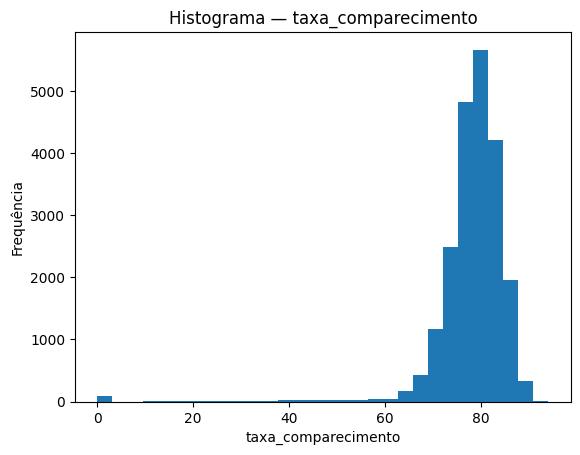

Assimetria: -5.130740843833425
Curtose: 43.166111059762066


In [ ]:
# Histograma da métrica alvo (um gráfico por figura)
plt.figure()
zonas[target].dropna().plot(kind="hist", bins=30, title=f"Histograma — {target}")
plt.xlabel(target)
plt.ylabel("Frequência")
plt.show()

print("Assimetria:", zonas[target].skew())
print("Curtose:", zonas[target].kurt())

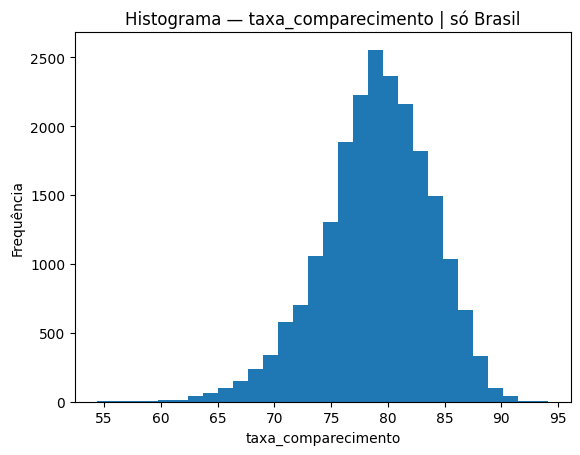

Sem o exterior -> Assimetria: -0.458342139369814
Sem o exterior -> Curtose: 0.39259413107390984
Sem o exterior -> Média: 78.99247935812332


In [ ]:
# O mesmo histograma sem as zonas do exterior ('ZZ')
brasil = zonas[zonas["sg_uf"] != "ZZ"]

plt.figure()
brasil[target].dropna().plot(kind="hist", bins=30, title=f"Histograma — {target} | só Brasil")
plt.xlabel(target)
plt.ylabel("Frequência")
plt.show()

print("Sem o exterior -> Assimetria:", brasil[target].skew())
print("Sem o exterior -> Curtose:", brasil[target].kurt())
print("Sem o exterior -> Média:", brasil[target].mean())

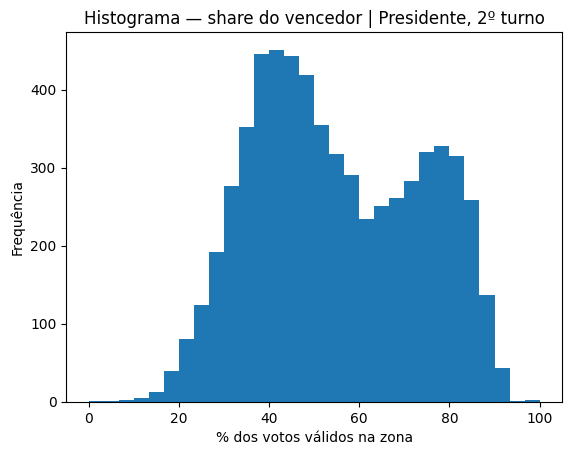

Zonas em que o vencedor passou de 50%: 54.04329831263929
Assimetria: 0.13105137044568896


In [ ]:
# Histograma do share do vencedor em cada zona (Presidente, 2º turno)
plt.figure()
venc_2t["share"].dropna().plot(kind="hist", bins=30, title="Histograma — share do vencedor | Presidente, 2º turno")
plt.xlabel("% dos votos válidos na zona")
plt.ylabel("Frequência")
plt.show()

print("Zonas em que o vencedor passou de 50%:", (venc_2t["share"] > 50).mean() * 100)
print("Assimetria:", venc_2t["share"].skew())

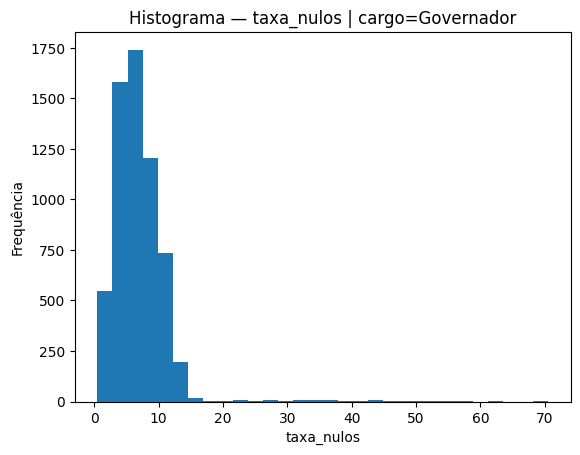

Governador -> assimetria: 5.036970299727197


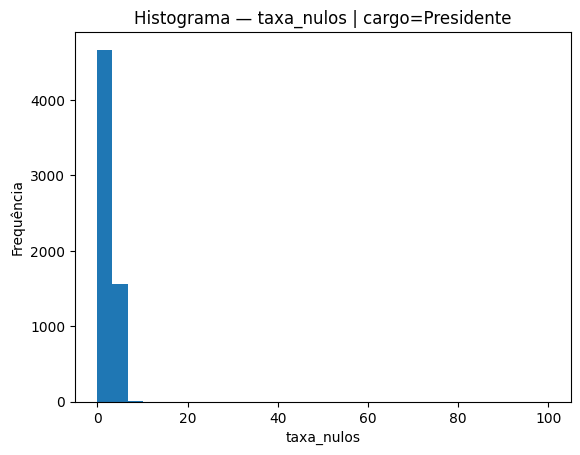

Presidente -> assimetria: 34.67557293371039


In [ ]:
# Histograma dos votos nulos por cargo (1º turno), um de cada vez, sem subplots
zonas_1turno = zonas[zonas["nr_turno"] == 1]
for cargo in zonas_1turno["ds_cargo"].unique():
    subset = zonas_1turno[zonas_1turno["ds_cargo"] == cargo]["taxa_nulos"].dropna()
    plt.figure()
    subset.plot(kind="hist", bins=30, title=f"Histograma — taxa_nulos | cargo={cargo}")
    plt.xlabel("taxa_nulos")
    plt.ylabel("Frequência")
    plt.show()
    print(cargo, "-> assimetria:", subset.skew())

In [ ]:
# Por que a assimetria dos nulos de Presidente é tão alta? Vendo as zonas com mais nulos:
display(pres_1t.sort_values("taxa_nulos", ascending=False)
        [["nm_municipio", "sg_uf", "qt_comparecimento", "taxa_nulos"]].head(3))

pres_1t_brasil = pres_1t[pres_1t["sg_uf"] != "ZZ"]
print("Presidente sem o exterior -> assimetria:", pres_1t_brasil["taxa_nulos"].skew())

,nm_municipio,sg_uf,qt_comparecimento,taxa_nulos
20040,CARACAS,ZZ,5,100.000000
21031,CONGONHAS DO NORTE,MG,2961,8.544411
20928,FRUTA DE LEITE,MG,3192,8.145363


Presidente sem o exterior -> assimetria: 0.6490619920090529


> **Interpretação**
> - Com todas as zonas, o comparecimento tem **assimetria de -5,1** e **curtose de 43**: quase tudo concentrado perto de 79%, com uma cauda longa à esquerda. **Não é uma distribuição normal.**
> - **Sem o exterior**, a assimetria cai para **-0,46** e a curtose para **0,39**, com média de **79,0%**: o histograma vira quase um sino. Ou seja, **quem cria a cauda são as zonas do exterior, não o Brasil**.
> - O share do vencedor no 2º turno vai de 0% a 100% e é quase simétrico (assimetria perto de 0). Ele passou de 50% em **54% das zonas**: vitória apertada, com zonas divididas dos dois lados.
> - O voto nulo tem cauda para a **direita**: a maioria das zonas tem pouco nulo e poucas têm muito. Em **Governador** os valores chegam a **70,5%** (a seção 10 explica).
> - A assimetria dos nulos de **Presidente** sai altíssima (**34,7**) por causa de **uma única zona**: Caracas, no exterior, onde 5 pessoas votaram e todos os votos foram nulos (100%). Sem o exterior, cai para **0,65**. Isso mostra como a assimetria é sensível a um valor extremo.

## 8) Relações entre Variáveis (correlação e scatter)

> **Lembrete:** a **correlação** vai de -1 a +1. Perto de +1, as duas variáveis sobem juntas; perto de -1, quando uma sobe a outra desce; perto de 0, não há relação em linha reta. **Correlação não prova causa.**

,share,taxa_abstencao,taxa_brancos,taxa_nulos,qt_aptos_tot
share,1.000000,0.129387,-0.261048,0.315897,-0.157558
taxa_abstencao,0.129387,1.000000,-0.088155,-0.009166,-0.127500
taxa_brancos,-0.261048,-0.088155,1.000000,0.333453,0.232333
taxa_nulos,0.315897,-0.009166,0.333453,1.000000,0.184328
qt_aptos_tot,-0.157558,-0.127500,0.232333,0.184328,1.000000


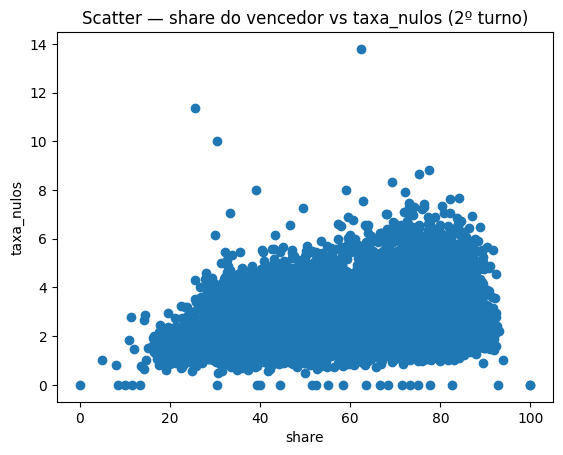

In [ ]:
# Correlação de Pearson entre o share do vencedor e o perfil da zona (2º turno)
cols_corr = ["share", "taxa_abstencao", "taxa_brancos", "taxa_nulos", "qt_aptos_tot"]
corr = venc_2t[cols_corr].corr(method="pearson")
display(corr)

# Scatter: share do vencedor x votos nulos
plt.figure()
plt.scatter(venc_2t["share"], venc_2t["taxa_nulos"])
plt.title("Scatter — share do vencedor vs taxa_nulos (2º turno)")
plt.xlabel("share")
plt.ylabel("taxa_nulos")
plt.show()

In [ ]:
# A mesma correlação calculada dentro de cada região.
# Se a relação fosse "de verdade", ela deveria aparecer em todas as regiões.
for regiao, subset in venc_2t.groupby("nm_regiao"):
    r_nulos = subset["share"].corr(subset["taxa_nulos"])
    r_brancos = subset["share"].corr(subset["taxa_brancos"])
    print(f"{regiao:13s} share médio={subset['share'].mean():5.1f}  "
          f"r(share, nulos)={r_nulos:6.3f}  r(share, brancos)={r_brancos:6.3f}")

CENTRO-OESTE  share médio= 42.8  r(share, nulos)= 0.314  r(share, brancos)= 0.105
EXTERIOR      share médio= 52.6  r(share, nulos)= 0.072  r(share, brancos)= 0.004
NORDESTE      share médio= 75.6  r(share, nulos)=-0.147  r(share, brancos)=-0.361
NORTE         share médio= 53.6  r(share, nulos)= 0.231  r(share, brancos)=-0.332
SUDESTE       share médio= 48.5  r(share, nulos)=-0.132  r(share, brancos)=-0.297
SUL           share médio= 40.1  r(share, nulos)= 0.170  r(share, brancos)= 0.147


> **Interpretação: a correlação que muda de sinal**
> - No Brasil todo, **onde o vencedor teve mais votos houve mais voto nulo (r = +0,32)** e **menos voto branco (r = -0,26)**.
> - Mas, **dentro de cada região**, a relação com o nulo **inverte** no Nordeste (**-0,15**) e no Sudeste (**-0,13**), e continua positiva no Sul e no Centro-Oeste.
> - O motivo: o **Nordeste** tem, ao mesmo tempo, o maior share do vencedor (**75,6%** em média) **e** taxas de nulo mais altas. Misturando todas as regiões, aparece uma correlação que não existe da mesma forma dentro delas.
> - Esse fenômeno se chama **Paradoxo de Simpson**: uma correlação no total pode vir da mistura de grupos diferentes, e não de uma ligação real entre as variáveis.
> - O tamanho da zona (`qt_aptos_tot`) quase não se relaciona com nada: todas as correlações ficam abaixo de 0,25.

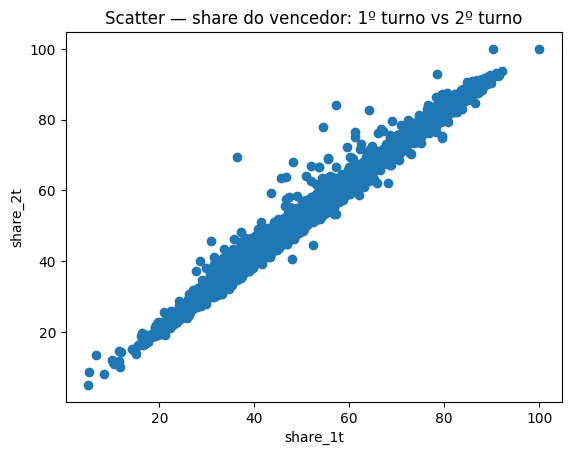

Correlação entre os turnos: 0.9953954807213965
Ganho médio do 1º para o 2º turno (pontos): 1.8131503762590717


,ganho_medio
nm_regiao,
EXTERIOR,6.150782
NORDESTE,2.329959
SUDESTE,2.002459
NORTE,1.428911
CENTRO-OESTE,1.086195
SUL,0.704052


In [ ]:
# O eleitor mudou de voto entre os turnos?
# Juntamos (merge) o share do vencedor no 1º e no 2º turno, zona por zona.
# suffixes dá um "sobrenome" às colunas que têm o mesmo nome nas duas tabelas.
turnos = venc_1t[["cd_municipio", "nr_zona", "share"]].merge(
    venc_2t[["cd_municipio", "nr_zona", "share", "nm_regiao"]],
    on=["cd_municipio", "nr_zona"], suffixes=("_1t", "_2t"))

plt.figure()
plt.scatter(turnos["share_1t"], turnos["share_2t"])
plt.title("Scatter — share do vencedor: 1º turno vs 2º turno")
plt.xlabel("share_1t")
plt.ylabel("share_2t")
plt.show()

print("Correlação entre os turnos:", turnos["share_1t"].corr(turnos["share_2t"]))

turnos["ganho"] = turnos["share_2t"] - turnos["share_1t"]
print("Ganho médio do 1º para o 2º turno (pontos):", turnos["ganho"].mean())
display(turnos.groupby("nm_regiao")["ganho"].mean().sort_values(ascending=False).to_frame("ganho_medio"))

> **Interpretação**
> - A correlação entre o share do vencedor no 1º e no 2º turno é **0,995**, quase perfeita. No gráfico, os pontos formam praticamente uma linha reta.
> - Ou seja, **quase ninguém mudou de lado**: a zona que votou forte no vencedor no 1º turno fez o mesmo no 2º.
> - O ganho médio foi de só **1,8 ponto** por zona, vindo de quem tinha votado em outros candidatos no 1º turno. O maior ganho foi no **Exterior (+6,2)** e o menor no **Sul (+0,7)**.

## 9) Segmentações (por região, estado, turno e candidato)

In [ ]:
# Por região — Presidente, 1º turno (a mesma eleição em todo o país, dá para comparar)
seg_regiao = venc_1t.groupby("nm_regiao")[["taxa_comparecimento", "taxa_brancos", "taxa_nulos"]].mean()
display(seg_regiao.sort_values("taxa_comparecimento", ascending=False))

# Por estado — comparecimento médio
seg_uf = pres_1t.groupby("sg_uf")["taxa_comparecimento"].mean().sort_values(ascending=False)
display(seg_uf.to_frame("comparecimento_medio"))

,taxa_comparecimento,taxa_brancos,taxa_nulos
nm_regiao,,,
SUL,82.041939,1.620540,1.841938
NORDESTE,79.288376,1.192808,3.132854
NORTE,78.078121,0.677971,1.870256
SUDESTE,77.106635,1.805353,3.204623
CENTRO-OESTE,76.801118,1.001385,1.857712
EXTERIOR,35.888462,1.456058,2.291839


,comparecimento_medio
sg_uf,
RR,84.588336
RS,82.919220
SC,82.737040
DF,82.568060
RN,82.534982
PI,82.017726
PB,81.283302
CE,81.226710
TO,81.063297


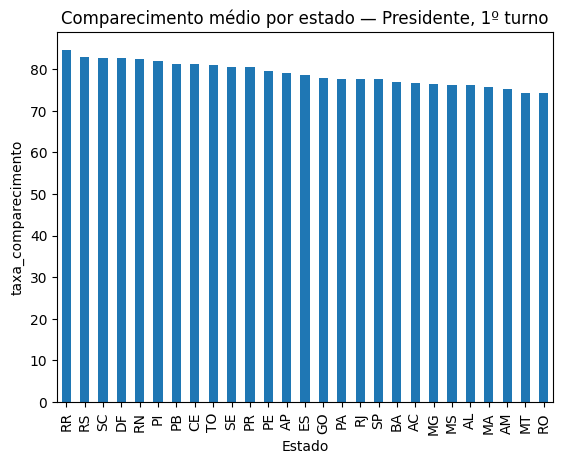

In [ ]:
# Gráfico de barras do comparecimento por estado (sem o exterior)
plt.figure()
seg_uf.drop("ZZ").plot(kind="bar", title="Comparecimento médio por estado — Presidente, 1º turno")
plt.xlabel("Estado")
plt.ylabel("taxa_comparecimento")
plt.xticks(rotation=90)
plt.show()

In [ ]:
# Por turno — Presidente (todos os estados votaram nos dois turnos)
display(zonas[zonas["ds_cargo"] == "Presidente"].groupby("nr_turno")[taxas].mean())

# Por turno — Governador. Só 12 estados tiveram 2º turno; para comparar de forma justa,
# usamos o merge para ficar só com esses 12 estados nos dois turnos.
estados_2t = pd.DataFrame({"sg_uf": gov_2t["sg_uf"].unique()})
gov_12 = zonas[zonas["ds_cargo"] == "Governador"].merge(estados_2t, on="sg_uf")
display(gov_12.groupby("nr_turno")[taxas].mean())

,taxa_comparecimento,taxa_abstencao,taxa_brancos,taxa_nulos,taxa_validos
nr_turno,,,,,
1.0,77.616718,22.383282,1.420036,2.673975,95.905989
2.0,77.700510,22.299490,1.258627,2.823395,95.917978


,taxa_comparecimento,taxa_abstencao,taxa_brancos,taxa_nulos,taxa_validos
nr_turno,,,,,
1.0,79.242045,20.757955,4.388011,6.872125,88.731637
2.0,79.651794,20.348206,2.713023,4.971611,92.315366


In [ ]:
# Governador — resultado de cada eleição estadual
cand_gov = base[base["ds_cargo"] == "Governador"]
zonas_gov = zonas[zonas["ds_cargo"] == "Governador"]

# Votos válidos de cada estado em cada turno
validos_uf = zonas_gov.groupby(["nr_turno", "sg_uf"])["qt_votos_validos"].sum()

# Eleitos: votos no estado e % dos votos válidos
eleitos = cand_gov[cand_gov["ds_sit_totalizacao"] == "Eleito"]
votos_eleitos = eleitos.groupby(["nr_turno", "sg_uf", "nm_candidato", "sg_partido"])["qt_votos_nominais"].sum()
pct_eleitos = votos_eleitos / validos_uf * 100   # o pandas alinha pelo turno e pelo estado

print("Governadores eleitos no 1º turno:", len(eleitos[eleitos["nr_turno"] == 1]["nm_candidato"].unique()))
print("Governadores eleitos no 2º turno:", len(eleitos[eleitos["nr_turno"] == 2]["nm_candidato"].unique()))
display(pct_eleitos.sort_values().to_frame("pct_no_estado"))

Governadores eleitos no 1º turno: 15
Governadores eleitos no 2º turno: 12


pct_no_estado
nr_turno sg_uf nm_candidato                        sg_partido                  
1.0      DF    IBANEIS ROCHA BARROS JÚNIOR         MDB                50.308844
         MA    CARLOS ORLEANS BRANDÃO JÚNIOR       PSB                51.289851
2.0      SE    FÁBIO CRUZ MITIDIERI                PSD                51.695033
1.0      GO    RONALDO RAMOS CAIADO                UNIÃO              51.809067
2.0      AL    PAULO SURUAGY DO AMARAL DANTAS      MDB                52.330044
         RO    MARCOS JOSÉ ROCHA DOS SANTOS        UNIÃO              52.466211
         PB    JOÃO AZEVEDO LINS FILHO             PSB                52.512842
         BA    JERÔNIMO RODRIGUES SOUZA            PT                 52.789053
1.0      AP    CLÉCIO LUÍS VILHENA VIEIRA          SOLIDARIEDADE      53.770530
2.0      ES    JOSÉ RENATO CASAGRANDE              PSB                53.795212
1.0      CE    ELMANO DE FREITAS DA COSTA          PT                 54.017279
2.0      SP    TARCISIO GOMES DE FREITAS           REPUBLICANOS       55.271157
1.0      MG    ROMEU ZEMA NETO                     NOVO               56.195359
         RR    ANTONIO OLIVERIO GARCIA DE ALMEIDA  PP                 56.472262
2.0      AM    WILSON MIRANDA LIMA                 UNIÃO              56.653637
1.0      AC    GLADSON DE LIMA CAMELI              PP                 56.751055
2.0      MS    EDUARDO CORREA RIEDEL               PSDB               56.903254
         RS    EDUARDO FIGUEIREDO CAVALHEIRO LEITE PSDB               57.121243
1.0      PI    RAFAEL TAJRA FONTELES               PT                 57.620304
         TO    WANDERLEI BARBOSA CASTRO            REPUBLICANOS       58.164546
         RN    MARIA DE FATIMA BEZERRA             PT                 58.311162
         RJ    CLÁUDIO BOMFIM DE CASTRO E SILVA    PL                 58.687184
2.0      PE    RAQUEL TEIXEIRA LYRA LUCENA         PSDB               58.702931
1.0      MT    MAURO MENDES FERREIRA               UNIÃO              68.452327
         PR    CARLOS ROBERTO MASSA JUNIOR         PSD                69.762061
         PA    HELDER ZAHLUTH BARBALHO             MDB                70.407344
2.0      SC    JORGINHO DOS SANTOS MELLO           PL                 70.701190
1.0      AL    NaN                                 NaN                      NaN
         AM    NaN                                 NaN                      NaN
         BA    NaN                                 NaN                      NaN
         ES    NaN                                 NaN                      NaN
         MS    NaN                                 NaN                      NaN
         PB    NaN                                 NaN                      NaN
         PE    NaN                                 NaN                      NaN
         RO    NaN                                 NaN                      NaN
         RS    NaN                                 NaN                      NaN
         SC    NaN                                 NaN                      NaN
         SE    NaN                                 NaN                      NaN
         SP    NaN                                 NaN                      NaN

In [ ]:
# Diferença entre 1º e 2º colocado nos estados com 2º turno (quanto menor, mais disputada)
cand_gov_2t = cand_gov[cand_gov["nr_turno"] == 2]
pct_2t = cand_gov_2t.groupby(["sg_uf", "nm_candidato"])["qt_votos_nominais"].sum() / validos_uf[2] * 100

estados, margens = [], []
for uf in cand_gov_2t["sg_uf"].unique():
    valores = pct_2t[uf].sort_values(ascending=False).values
    estados.append(uf)
    margens.append(valores[0] - valores[1])

margem = pd.DataFrame({"estado": estados, "margem_pontos": margens})
display(margem.sort_values("margem_pontos"))

,estado,margem_pontos
6,SE,3.390065
4,AL,4.660087
0,RO,4.932421
2,PB,5.025685
5,BA,5.578106
8,ES,7.590425
9,SP,10.542315
1,AM,13.307274
7,MS,13.806507
11,RS,14.242487


In [ ]:
# Por situação do candidato no 1º turno: % dos votos válidos do estado
cand_gov_1t = cand_gov[cand_gov["nr_turno"] == 1]

for situacao in cand_gov_1t["ds_sit_totalizacao"].unique():
    subset = cand_gov_1t[cand_gov_1t["ds_sit_totalizacao"] == situacao]
    pct = subset.groupby(["sg_uf", "nm_candidato"])["qt_votos_nominais"].sum() / validos_uf[1] * 100
    print(f"{situacao:14s} candidatos={len(pct):3d}  média={pct.mean():5.1f}%  mediana={pct.median():5.1f}%")

Não Eleito     candidatos=174  média=  5.7%  mediana=  0.6%
Segundo turno  candidatos= 24  média= 34.6%  mediana= 38.0%
Eleito         candidatos= 15  média= 58.1%  mediana= 56.8%


> **Interpretação**
> - **Por região:** o **Sul** tem o maior comparecimento (**82,0%**) e o **Centro-Oeste** o menor dentro do Brasil (**76,8%**). O **Exterior** fica muito abaixo, com **35,9%**.
> - **Por estado:** **RR (84,6%)**, **RS (82,9%)**, **SC (82,7%)** e **DF (82,6%)** lideram; **RO (74,3%)**, **MT (74,3%)** e **AM (75,2%)** ficam no fim. São mais de 10 pontos de diferença num país onde votar é obrigatório.
> - **Por turno (Presidente):** o comparecimento praticamente não mudou (**77,62% → 77,70%**). Os brancos caíram (**1,42% → 1,26%**) e os nulos subiram (**2,67% → 2,82%**).
> - **Por turno (Governador, só nos 12 estados com 2º turno):** brancos caíram de **4,39% para 2,71%** e nulos de **6,87% para 4,97%**. Com só dois nomes na urna, menos gente anulou.
> - **Governadores:** **15 eleitos no 1º turno** e **12 no 2º**. A disputa mais apertada foi em **Sergipe (3,4 pontos)** e a mais folgada em **Santa Catarina (41,4 pontos)**.
> - **Por situação (1º turno):** o eleito teve mediana de **56,8%** dos votos do estado; quem foi para o 2º turno, **38,0%**; e quem não foi eleito, **0,6%**. A maioria dos 213 candidatos teve votação muito pequena.

## 10) Outliers (IQR e Z-Score)

In [ ]:
# --- IQR ---
Q1 = zonas[target].quantile(0.25)
Q3 = zonas[target].quantile(0.75)
IQR = Q3 - Q1
lim_inf = Q1 - 1.5 * IQR
lim_sup = Q3 + 1.5 * IQR
print(f"Limites: abaixo de {lim_inf:.2f} ou acima de {lim_sup:.2f}")

outliers_iqr = zonas[(zonas[target] < lim_inf) | (zonas[target] > lim_sup)]
print("Outliers (IQR) para", target, ":", outliers_iqr.shape[0])

# Em quais estados estão os outliers?
# Truque: True vale 1 e False vale 0, então somar True/False conta os outliers.
zonas["outlier"] = (zonas[target] < lim_inf) | (zonas[target] > lim_sup)
display(zonas.groupby("sg_uf")["outlier"].sum().sort_values(ascending=False).head(6).to_frame("outliers"))

# --- Z-Score ---
x = zonas[target]
z = (x - x.mean()) / x.std(ddof=0)
outliers_z = zonas[abs(z) >= 3]
print("Outliers (|z| >= 3) para", target, ":", outliers_z.shape[0])

Limites: abaixo de 66.43 ou acima de 91.77
Outliers (IQR) para taxa_comparecimento : 606


,outliers
sg_uf,
ZZ,350
MG,120
AM,40
BA,28
MA,12
AP,10


Outliers (|z| >= 3) para taxa_comparecimento : 280


In [ ]:
colunas_ver = ["nm_municipio", "sg_uf", "ds_cargo", "nr_turno", "qt_aptos_tot", "qt_comparecimento", target]

print("Menores comparecimentos:")
display(outliers_iqr.sort_values(target)[colunas_ver].head(8))

print("Acima do limite superior:")
display(outliers_iqr[outliers_iqr[target] > lim_sup][colunas_ver])

Menores comparecimentos:


,nm_municipio,sg_uf,ds_cargo,nr_turno,qt_aptos_tot,qt_comparecimento,taxa_comparecimento
9272,CASTRIES,ZZ,Presidente,2.0,1,0,0.0
9271,YANGON,ZZ,Presidente,2.0,8,0,0.0
9270,BAMAKO,ZZ,Presidente,2.0,1,0,0.0
9269,LILONGUE,ZZ,Presidente,2.0,4,0,0.0
9267,ADIS ABEBA,ZZ,Presidente,2.0,2,0,0.0
9268,ST GEORGES DE LOYAPOCK,ZZ,Presidente,2.0,11,0,0.0
5320,BAKU,ZZ,Presidente,2.0,2,0,0.0
4830,GABORONE,ZZ,Presidente,2.0,7,0,0.0


Acima do limite superior:


,nm_municipio,sg_uf,ds_cargo,nr_turno,qt_aptos_tot,qt_comparecimento,taxa_comparecimento
2430,CERRO GRANDE,RS,Governador,2.0,2575,2424,94.135922
8185,CERRO GRANDE,RS,Presidente,2.0,2575,2424,94.135922


In [ ]:
# Outliers de voto nulo (mesmo método IQR)
Q1n = zonas["taxa_nulos"].quantile(0.25)
Q3n = zonas["taxa_nulos"].quantile(0.75)
lim_sup_nulos = Q3n + 1.5 * (Q3n - Q1n)

outliers_nulos = zonas[zonas["taxa_nulos"] > lim_sup_nulos]
print(f"Zonas com nulo acima de {lim_sup_nulos:.2f}%:", outliers_nulos.shape[0])
display(outliers_nulos.sort_values("taxa_nulos", ascending=False)
        [["nm_municipio", "sg_uf", "ds_cargo", "nr_turno", "qt_comparecimento", "taxa_nulos"]].head(8))

# Média de nulos para Governador (1º turno), por estado
display(gov_1t.groupby("sg_uf")["taxa_nulos"].mean().sort_values(ascending=False).head(6).to_frame("nulos_gov_1t"))
print("Média nacional de nulos para Governador (1º turno):", gov_1t["taxa_nulos"].mean())

Zonas com nulo acima de 10.02%: 979


,nm_municipio,sg_uf,ds_cargo,nr_turno,qt_comparecimento,taxa_nulos
20040,CARACAS,ZZ,Presidente,1.0,5,100.000000
13975,MALHADOR,SE,Governador,1.0,8292,70.549928
13965,ITABAIANA,SE,Governador,1.0,61494,61.274271
13973,MACAMBIRA,SE,Governador,1.0,5307,58.394573
13954,NOSSA SENHORA APARECIDA,SE,Governador,1.0,6071,58.211168
13942,AREIA BRANCA,SE,Governador,1.0,11847,58.200388
13977,MOITA BONITA,SE,Governador,1.0,7795,57.793457
13996,RIBEIRÓPOLIS,SE,Governador,1.0,11929,57.791936


,nulos_gov_1t
sg_uf,
SE,36.557561
AL,10.983079
PB,10.614456
PE,10.187295
MG,9.446956
MA,9.425279


Média nacional de nulos para Governador (1º turno): 6.980534174871301


> **Estudo de caso: por que Sergipe?**
>
> Sergipe teve **36,6% de votos nulos para Governador** no 1º turno, contra **6,98%** de média nacional — mais de 5 vezes mais. Em Malhador (SE) chegou a **70,5%**. O segundo estado, Alagoas, ficou em 11,0%.
>
> Não foi erro nem protesto: o candidato mais votado do estado teve o **registro da candidatura negado pela Justiça Eleitoral**, e todos os votos dados a ele **foram anulados** ([CNN Brasil](https://www.cnnbrasil.com.br/politica/com-candidato-mais-votado-barrado-pela-justica-eleicao-para-governador-em-sergipe-teve-39-de-votos-nulos/), [TRE-SE](https://www.tre-se.jus.br/comunicacao/noticias/2022/Setembro/por-unanimidade-tre-se-nega-registro-de-candidatura-de-valmir-de-francisquinho)).
>
> Um detalhe confirma isso na nossa base: os votos desse candidato **não aparecem no arquivo de candidatos**, só como "nulos" no arquivo de zonas. É um bom exemplo de por que vale usar os dois tipos de arquivo juntos. E, no 2º turno, Sergipe teve a **disputa mais apertada do país (3,4 pontos)**.

> **Discussão: outlier é erro ou caso interessante?**
> - Os **606 outliers de comparecimento pelo IQR** não são erro. O z-score aponta só **280**, porque os próprios extremos aumentam o desvio-padrão e "escondem" parte deles; por isso o IQR funciona melhor aqui.
> - **De onde vêm:** **350 são do exterior**, **120 de Minas Gerais** e **40 do Amazonas**. No exterior, muitos postos consulares têm pouquíssimos eleitores e ninguém foi votar. Em MG e AM são municípios do interior, com mais dificuldade de acesso.
> - **No topo:** só um município passa do limite superior: **Cerro Grande (RS), com 94,1%** no 2º turno, uma cidade com cerca de 2,6 mil eleitores.
> - **Decisão:** **não remover**. Separar o exterior (como na seção 7) já resolve a distorção nas estatísticas, e os outliers continuam disponíveis para análise, porque são as partes mais interessantes do dado.

## 11) Boxplot comparativo

/tmp/ipykernel_1139/2849832450.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(grupos, labels=labels, showfliers=True)


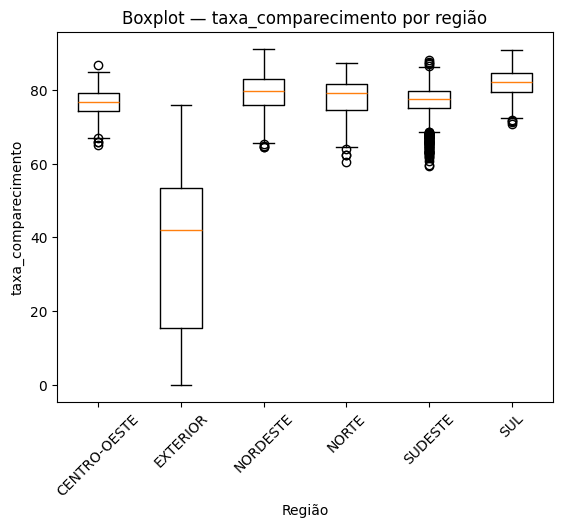

In [ ]:
# Boxplot do comparecimento por região (Presidente, 1º turno) — um gráfico por figura
grupos = []
labels = []
for regiao, subset in venc_1t.groupby("nm_regiao"):
    valores = subset[target].dropna().values
    if len(valores) > 0:
        grupos.append(valores)
        labels.append(regiao)

plt.figure()
plt.boxplot(grupos, labels=labels, showfliers=True)
plt.title(f"Boxplot — {target} por região")
plt.xlabel("Região")
plt.ylabel(target)
plt.xticks(rotation=45)
plt.show()

/tmp/ipykernel_1139/376776644.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(grupos, labels=labels, showfliers=True)


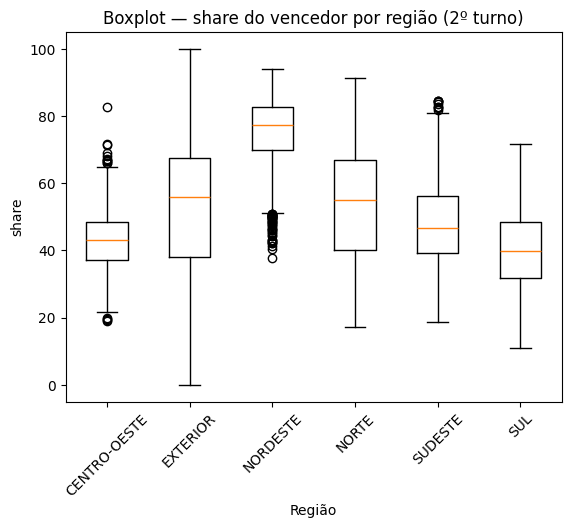

,mediana_share
nm_regiao,
CENTRO-OESTE,43.006694
EXTERIOR,55.790945
NORDESTE,77.313185
NORTE,54.890913
SUDESTE,46.786264
SUL,39.872768


In [ ]:
# Boxplot do share do vencedor por região (Presidente, 2º turno)
grupos = []
labels = []
for regiao, subset in venc_2t.groupby("nm_regiao"):
    valores = subset["share"].dropna().values
    if len(valores) > 0:
        grupos.append(valores)
        labels.append(regiao)

plt.figure()
plt.boxplot(grupos, labels=labels, showfliers=True)
plt.title("Boxplot — share do vencedor por região (2º turno)")
plt.xlabel("Região")
plt.ylabel("share")
plt.xticks(rotation=45)
plt.show()

display(venc_2t.groupby("nm_regiao")["share"].median().to_frame("mediana_share"))

/tmp/ipykernel_1139/2419690890.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(grupos, labels=labels, showfliers=False)


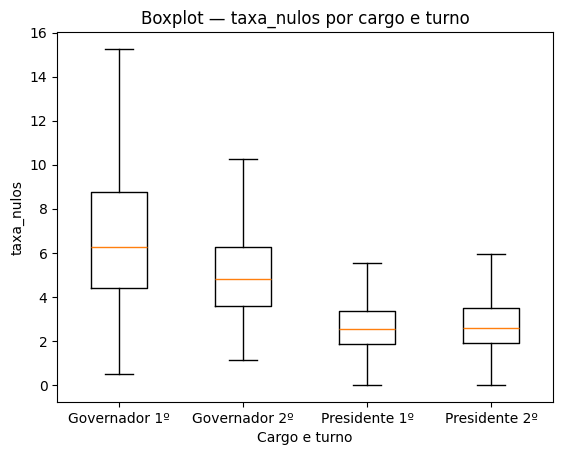

In [ ]:
# Boxplot dos votos nulos por cargo e turno
grupos = []
labels = []
for (cargo, turno), subset in zonas.groupby(["ds_cargo", "nr_turno"]):
    valores = subset["taxa_nulos"].dropna().values
    if len(valores) > 0:
        grupos.append(valores)
        labels.append(f"{cargo} {turno:.0f}º")

plt.figure()
plt.boxplot(grupos, labels=labels, showfliers=False)
plt.title("Boxplot — taxa_nulos por cargo e turno")
plt.xlabel("Cargo e turno")
plt.ylabel("taxa_nulos")
plt.xticks(rotation=0)
plt.show()

> **Leitura dos boxplots**
> - **Comparecimento por região:** o **Sul** tem a caixa mais alta; o **Exterior** fica muito abaixo de todas, quase como outro conjunto de dados.
> - **Share do vencedor por região:** é o gráfico que melhor resume a eleição. No **Nordeste** a caixa inteira fica acima de 50% (mediana de **77,3%**). No **Sul** (**39,9%**) e no **Centro-Oeste** (**43,0%**), a caixa fica quase toda abaixo de 50%. **Norte** e **Exterior** ficam divididos.
> - **Nulos por cargo e turno:** a caixa de **Governador no 1º turno** é a mais alta e a mais larga. No 2º turno ela desce; em Presidente, as caixas ficam baixas e estreitas nos dois turnos.

## 12) Síntese e Storytelling dos Achados

### Contexto & Objetivo
Usamos os **4 arquivos** do TSE sobre as Eleições 2022, só para **Presidente** e **Governador**: **21.658 registros de zonas** (quem votou) e **140.620 registros de candidatos** (em quem votou), unidos numa tabela só. A pergunta: **como o Brasil votou — quem foi às urnas, como o voto se dividiu e em quem?**

### Principais achados

1. **O comparecimento é parecido em todo o país.** Média de **78,3%**, mediana de **79,2%**, e metade das zonas entre **75,9% e 82,3%**. É uma das medidas mais estáveis da base (CV de **0,10**).

2. **O voto nulo é o que mais varia.** CV de **0,79**, quase 8 vezes o do comparecimento. E ele depende do cargo: **6,98%** para Governador contra **2,67%** para Presidente no 1º turno.

3. **O exterior é um mundo à parte.** Comparecimento de **35,9%**, menos da metade do pior estado. É ele que deixa a distribuição torta: com o exterior, assimetria de **-5,1**; sem ele, **-0,46**, quase uma curva normal.

4. **A região pesa mais que o tamanho da zona.** O **Sul** vota mais (**82,0%**) e o **Centro-Oeste** menos (**76,8%**). O tamanho da zona quase não tem relação com nada.

5. **A eleição presidencial foi dividida por região.** A mediana do share do vencedor no 2º turno foi de **77,3% no Nordeste** e **39,9% no Sul**. No total, ele venceu em **54% das zonas**.

6. **Quase ninguém mudou de lado entre os turnos.** Correlação de **0,995** entre o share do vencedor no 1º e no 2º turno. O comparecimento também ficou igual (**77,62% → 77,70%**).

7. **Cuidado com correlações no total (Paradoxo de Simpson).** No Brasil inteiro, share do vencedor e voto nulo andam juntos (**r = +0,32**), mas dentro do Nordeste e do Sudeste essa relação fica negativa. A correlação do total vinha da mistura das regiões.

8. **O maior outlier tem explicação jurídica.** Sergipe teve **36,6% de nulos para Governador** porque o candidato mais votado teve o registro negado e seus votos foram anulados. Os dados apontaram o lugar exato do fenômeno antes de qualquer pesquisa externa.

### Implicações práticas
- Campanhas de conscientização teriam mais efeito combatendo o **voto nulo em cargos estaduais** do que a abstenção, que já é baixa e parecida em todo lugar.
- O voto no **exterior** é onde há mais espaço para aumentar a participação.
- Uma taxa de nulos muito acima da média em um estado e cargo funciona como **alerta** de algum problema com candidaturas.

### Limitações
- Os dados são **por zona**, não por pessoa: não dá para saber idade, renda ou escolaridade de quem votou.
- A base tem só **2022**; sem outros anos, não dá para separar o que é padrão do que foi desta eleição.
- Não há dados socioeconômicos, então não dá para testar **por que** uma região vota diferente da outra.
- Ficaram de fora Senado e deputados: as conclusões valem para **Presidente e Governador**.

### Próximos passos
- Cruzar com dados do **IBGE** (renda, escolaridade, urbanização) por município.
- Comparar com **2018** para ver se o padrão por região se repete.
- Fazer um **teste de hipótese** para confirmar se as diferenças entre regiões são estatisticamente significativas.
